# Logistic Regression and Random Forest

Run after `notebooks/05_machine_learning/data_preparation/ml_data_preparation.ipynb`. This notebook contains the complete training code; it does not invoke a Python training script.

## Environment and repository

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "docs/predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
print("Repository:", ROOT)
print("Python:", platform.python_version())


Repository: C:\Users\LENOVO\OneDrive\Desktop\PTTK
Python: 3.14.6


## Libraries

Use the shared root requirements.txt and select its Python environment as the kernel.

In [2]:
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss, precision_recall_curve, precision_score, recall_score, f1_score, confusion_matrix


## Run folders

A fresh run ID keeps outputs from different executions separate. Use Restart Kernel and Run All for a new run.

In [3]:
RUN = datetime.now().strftime('%Y%m%d_%H%M%S_%f')

I = ROOT / 'docs'

T = ROOT / 'outputs/tables/machine_learning/ml_logistic_random_forest' / RUN

F = ROOT / 'outputs/figures/ml_logistic_random_forest' / RUN

M = ROOT / 'outputs/models/ml_logistic_random_forest' / RUN

for p in [T, F, M]:
    p.mkdir(parents=True, exist_ok=False)

if (T / 'selected_config.json').exists():
    raise RuntimeError('Completed run exists. Use a new independent folder for another experiment.')


## Load and audit shared inputs

Use all 21 predictors and the existing chronological split manifest. B/Test labels are checked for expected counts only.

In [4]:
features = pd.read_csv(I / 'predictor_list.csv').feature.tolist()

df = pd.read_csv(ROOT / 'data/processed/research_data_weather_price_holiday_assume_utc.csv')

manifest = pd.read_csv(ROOT / 'data/ml_preparation/split_manifest.csv')

assert df.order_id.is_unique and manifest.order_id.is_unique

assert len(features) == 21 and len(set(features)) == 21

selected = manifest[manifest.split.isin(['train', 'validation_a', 'validation_b', 'test'])][['order_id', 'split']]

d = selected.merge(df, on='order_id', how='left', validate='one_to_one', indicator=True)

assert d['_merge'].eq('both').all()

expected = {'train': (57449, 3720), 'validation_a': (7661, 387), 'validation_b': (3115, 180), 'test': (9445, 504)}

sets = {}

for s, (n, pos) in expected.items():
    z = d[d.split.eq(s)].copy()
    assert len(z) == n and z.is_late.notna().all() and z.is_late.isin([0, 1]).all() and (int(z.is_late.sum()) == pos)
    sets[s] = z

pd.DataFrame([{'split': s, 'n': len(z), 'late': int(z.is_late.sum())} for s, z in sets.items()]).to_csv(T / 'input_audit.csv', index=False)
display(pd.read_csv(T / "input_audit.csv"))


,split,n,late
0,train,57449,3720
1,validation_a,7661,387
2,validation_b,3115,180
3,test,9445,504


## Prepare features

Numeric imputation and categorical encoding are fitted later inside each training pipeline. Logistic Regression uses scaling; Random Forest does not.

In [5]:
cat = ['customer_state', 'purchase_weekday']

num = [f for f in features if f not in cat]

for s, z in sets.items():
    for c in cat:
        z[c] = z[c].map(lambda v: str(v) if pd.notna(v) else np.nan)
    for c in num:
        z[c] = pd.to_numeric(z[c], errors='raise').replace([np.inf, -np.inf], np.nan)

train = sets['train']

A = sets['validation_a']

B = sets['validation_b']

pd.DataFrame({'feature': features, 'missing_train': [train[c].isna().sum() for c in features], 'unique_train': [train[c].nunique() for c in features]}).to_csv(T / 'feature_audit.csv', index=False)

assert not train[features].isna().all().any(), 'Entirely missing training feature requires review'
display(pd.read_csv(T / "feature_audit.csv"))


,feature,missing_train,unique_train
0,distance_km_mean,300,54358
1,customer_state,0,27
2,item_count,0,16
3,seller_count,0,5
4,purchase_hour,0,24
5,purchase_weekday,0,7
6,estimated_window_days,0,94
7,items_value,0,5300
8,freight_value,0,5644
9,total_product_weight_g,16,2177


## Define fixed baselines

Seed 42; Logistic Regression C=1 and Random Forest 300 trees, min_samples_leaf=2. No weighting, tuning, calibration or threshold selection.

In [6]:
def pipeline(model, scale):
    numeric = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        numeric.append(('scaler', StandardScaler()))
    prep = ColumnTransformer([('numeric', Pipeline(numeric), num), ('category', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)], sparse_threshold=0)
    return Pipeline([('preprocessing', prep), ('classifier', model)])

def factory(name):
    if name == 'LogisticRegression':
        return LogisticRegression(max_iter=3000, C=1, solver='lbfgs', class_weight=None, random_state=42)
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight=None, random_state=42, n_jobs=4)
    raise ValueError(name)

def metrics(y, p, threshold=None):
    r = {'n': len(y), 'late': int(np.sum(y)), 'prevalence': float(np.mean(y)), 'AP': average_precision_score(y, p), 'ROC_AUC': roc_auc_score(y, p), 'Brier': brier_score_loss(y, p), 'LogLoss': log_loss(y, p, labels=[0, 1])}
    if threshold is not None:
        pred = p >= threshold
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        r.update(threshold=float(threshold), Precision=precision_score(y, pred, zero_division=0), Recall=recall_score(y, pred), F1=f1_score(y, pred), alert_rate=float(pred.mean()), TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))
    return r

def predictions(z, p, name, kind, t=None):
    return pd.DataFrame({'order_id': z.order_id.to_numpy(), 'split': z.split.to_numpy(), 'model': name, 'y_true': z.is_late.astype(int).to_numpy(), 'probability': p, 'prediction': np.nan if t is None else (p >= t).astype(int), 'threshold': np.nan if t is None else t, 'probability_type': kind})


## Fit Train and predict Validation A

Both models use the same training and validation orders. Saved pipelines must reproduce the probabilities.

In [7]:
rows = []

predictions_a = []

logs = []

for name in ['LogisticRegression', 'RandomForest']:
    print('Training ' + name, flush=True)
    model = pipeline(factory(name), name == 'LogisticRegression')
    start = time.perf_counter()
    model.fit(train[features], train.is_late.astype(int))
    elapsed = time.perf_counter() - start
    probabilities = model.predict_proba(A[features])[:, 1]
    rows.append(dict(model=name, split='validation_a', probability_type='raw', **metrics(A.is_late, probabilities)))
    predictions_a.append(predictions(A, probabilities, name, 'raw'))
    logs.append(dict(model=name, seed=42, training_seconds=elapsed, parameters=model.named_steps['classifier'].get_params()))
    joblib.dump(model, M / (name + '.joblib'))
    np.testing.assert_allclose(joblib.load(M / (name + '.joblib')).predict_proba(A[features])[:, 1], probabilities)


Training LogisticRegression


Training RandomForest


## Export results and provenance

Save metrics, predictions, parameters, input hashes and package versions.

In [8]:
pd.DataFrame(rows).to_csv(T / 'validation_a_metrics.csv', index=False)

pd.concat(predictions_a, ignore_index=True).to_csv(T / 'validation_predictions.csv', index=False)

(T / 'experiment_log.json').write_text(json.dumps(logs, indent=2, default=str), encoding='utf-8')

versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'joblib', 'matplotlib']}

(T / 'package_versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

paths = [ROOT / 'data/processed/research_data_weather_price_holiday_assume_utc.csv', ROOT / 'docs/predictor_list.csv', ROOT / 'data/ml_preparation/split_manifest.csv']

(T / 'input_hashes.json').write_text(json.dumps({str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}, indent=2), encoding='utf-8')
versions["python"] = platform.python_version()
(T / "package_versions.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")
metrics_table = pd.DataFrame(rows)
validation_predictions = pd.concat(predictions_a, ignore_index=True)


## Inspect validation results

AP is the primary comparison metric. Validation scores are not an independent test estimate.

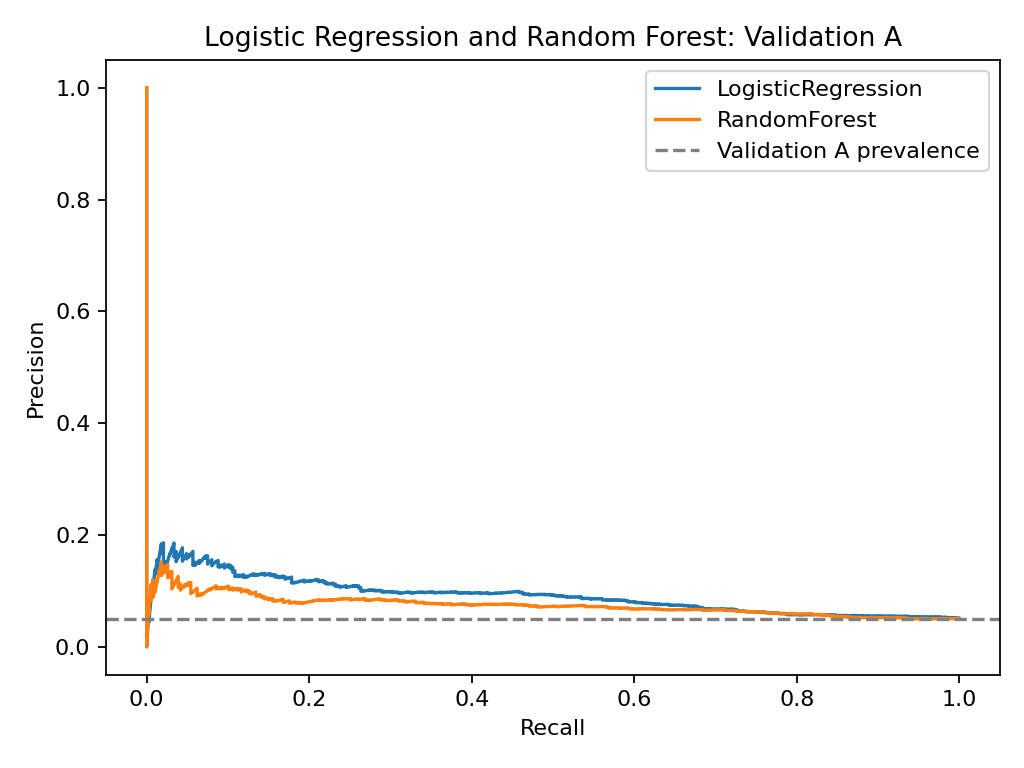

,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,LogisticRegression,validation_a,raw,7661,387,0.050516,0.091637,0.642369,0.047720,0.196408
1,RandomForest,validation_a,raw,7661,387,0.050516,0.074766,0.604052,0.048191,0.200893


Results: C:\Users\LENOVO\OneDrive\Desktop\PTTK\outputs\tables\ml_logistic_random_forest\20261111_144245_493286
Only Train fitted and Validation A scored; B/Test not scored.


In [9]:
fig, ax = plt.subplots()
for model_name, group in validation_predictions.groupby("model", sort=False):
    precision, recall, _ = precision_recall_curve(group.y_true, group.probability)
    ax.plot(recall, precision, label=model_name)
ax.axhline(float(A.is_late.mean()), linestyle="--", color="gray", label="Validation A prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Logistic Regression and Random Forest: Validation A")
ax.legend()
fig.tight_layout()
fig.savefig(F / "validation_a_pr_curve.png", dpi=160)
display(Image(filename=str(F / "validation_a_pr_curve.png")))
plt.close(fig)
display(metrics_table)
print("Results:", T)
print("Only Train fitted and Validation A scored; B/Test not scored.")
